In [1]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import zscore

In [2]:
current_dir = Path.cwd()
data_path = current_dir / "data"
data=pd.read_csv(data_path/"heart_disease_dataset.csv")
data.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [4]:
data[data.isna().any(axis=1)]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target


In [5]:
categorical_cols=['cp','restecg','slope','thal']
categorical_data=data[categorical_cols]
print(f'{len(categorical_cols)} categorical features:', '\n')
print(categorical_cols)

4 categorical features: 

['cp', 'restecg', 'slope', 'thal']


In [6]:
numerical_cols=['age','sex', 'trestbps','fbs','chol','thalach','exang','oldpeak','ca','target']
numerical_data=data[numerical_cols]
print(f'{len(numerical_cols)} numerical features:', '\n')
print(numerical_cols)

10 numerical features: 

['age', 'sex', 'trestbps', 'fbs', 'chol', 'thalach', 'exang', 'oldpeak', 'ca', 'target']


In [7]:
data.duplicated().sum()


np.int64(723)

In [8]:
cac_hang_trung = data[data.duplicated(keep=False)]
cac_hang_trung = cac_hang_trung.sort_values(by=list(data.columns))
cac_hang_trung 

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
60,29,1,1,130,204,0,0,202,0,0.0,2,0,2,1
64,29,1,1,130,204,0,0,202,0,0.0,2,0,2,1
118,29,1,1,130,204,0,0,202,0,0.0,2,0,2,1
668,29,1,1,130,204,0,0,202,0,0.0,2,0,2,1
12,34,0,1,118,210,0,1,192,0,0.7,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
535,76,0,2,140,197,0,2,116,0,1.1,1,0,2,1
965,76,0,2,140,197,0,2,116,0,1.1,1,0,2,1
160,77,1,0,125,304,0,0,162,1,0.0,2,3,2,0
162,77,1,0,125,304,0,0,162,1,0.0,2,3,2,0


Có các hàng dữ liệu bị trùng cần được xoá


##  Numerical Features

In [9]:
numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2
ca,1025.0,0.754146,1.030798,0.0,0.0,0.0,1.0,4.0
target,1025.0,0.513171,0.500070,0.0,0.0,1.0,1.0,1.0


In [10]:
numerical_data.var()

age           82.306450
sex            0.211944
trestbps     306.835410
fbs            0.127111
chol        2661.787109
thalach      529.263325
exang          0.223514
oldpeak        1.380750
ca             1.062544
target         0.250071
dtype: float64

- Biến chol, age,trestbps, thalach có phương sai lớn hơn đáng kể so với các biến còn lại
        
- *Cần phải có bước Feature Scaling trước khi đưa vào mô hình*

**Skew in numerical features**

In [11]:
numerical_data.skew()

age        -0.248866
sex        -0.851449
trestbps    0.739768
fbs         1.971339
chol        1.074073
thalach    -0.513777
exang       0.692655
oldpeak     1.210899
ca          1.261189
target     -0.052778
dtype: float64

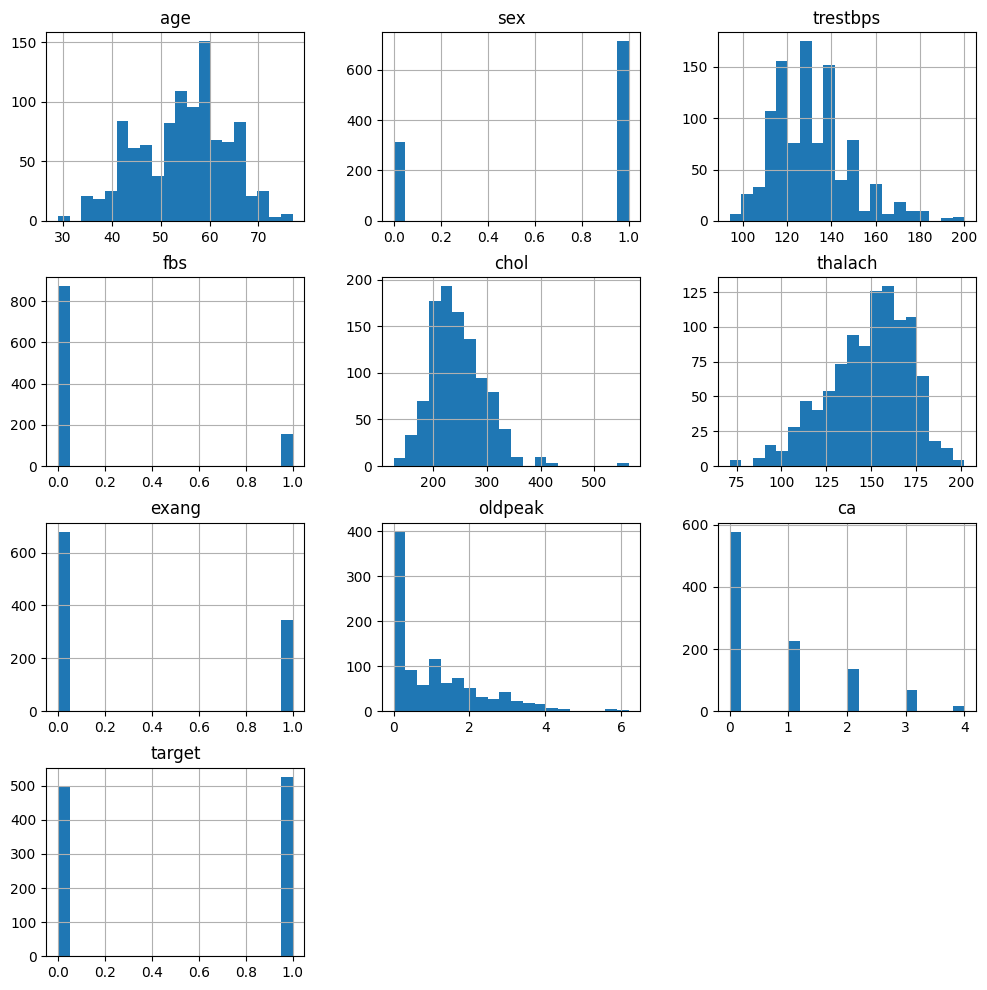

In [12]:
numerical_data.hist(figsize=(12,12),bins=20)
plt.savefig('outputs/eda/Histogram plot của numerical features.png',bbox_inches='tight')
plt.show()


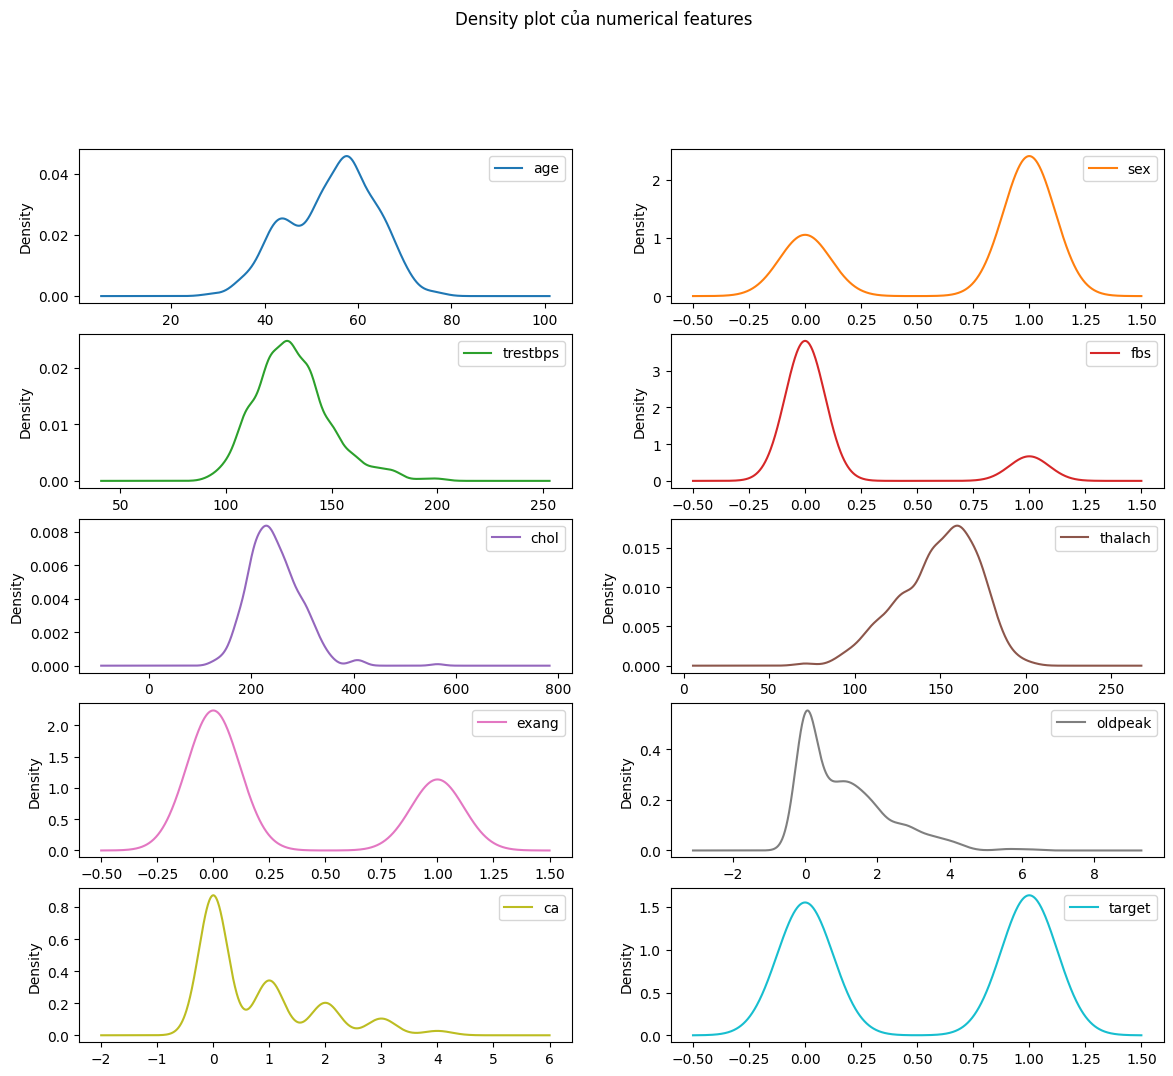

In [13]:
numerical_data.plot(kind='density',figsize=(14,14),subplots=True,layout=(6,2),title="Density plot của numerical features",sharex=False)
plt.savefig("outputs/eda/Desity plot của numerical features.png",bbox_inches='tight')
plt.show()

**Unique value**

In [14]:
numerical_data.nunique()

age          41
sex           2
trestbps     49
fbs           2
chol        152
thalach      91
exang         2
oldpeak      40
ca            5
target        2
dtype: int64

- Biến sex,fbs,exang là là các biến phân loại nhị phân 
- Các biến age có phân phối 2 đỉnh. Chỉ số độ lệch (skewness) là −0.24, cho thấy phân phối tương đối đối xứng nhưng hơi lệch nhẹ về bên trái
- Các biến trestbps, thalach và chol là các biến liên tục có dạng hình chuông nhưng không tuân theo phân phối chuẩn do có độ lệch
- Biến ca là biến rời rạc (discrete) nhận 4 giá trị duy nhất (từ 0 đến 3)
- Ca=4 là giá trị ngoại lai cần được thay thế ca=3


**Missing value**

In [15]:
numerical_data.isnull().sum()

age         0
sex         0
trestbps    0
fbs         0
chol        0
thalach     0
exang       0
oldpeak     0
ca          0
target      0
dtype: int64

**Outlier Detection**

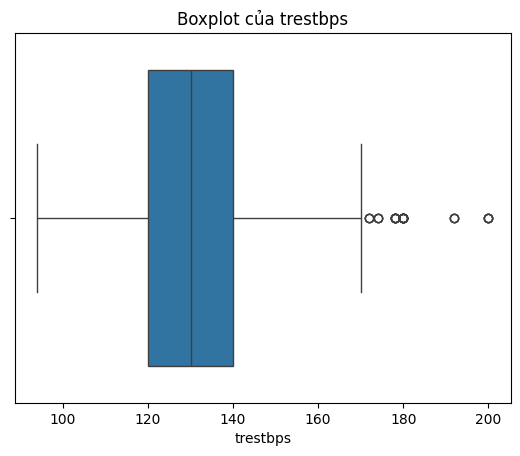

In [16]:
#Boxplot for Trestbps
sns.boxplot(x=numerical_data['trestbps'])
plt.title("Boxplot của trestbps")
plt.savefig("outputs/eda/Boxplot của trestbps.png")
plt.show()

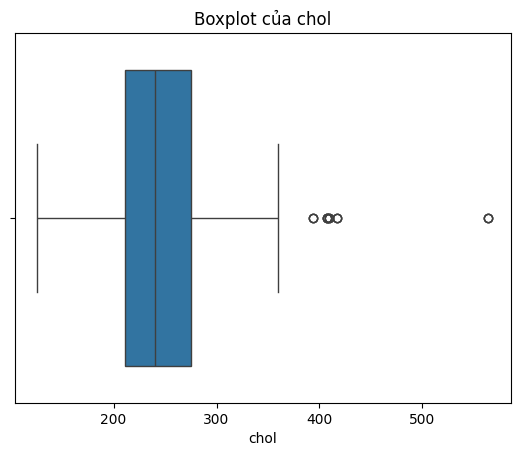

In [17]:
##Boxplot for chol
sns.boxplot(x=numerical_data['chol'])
plt.title("Boxplot của chol")
plt.savefig("outputs/eda/Boxplot của chol.png")
plt.show()

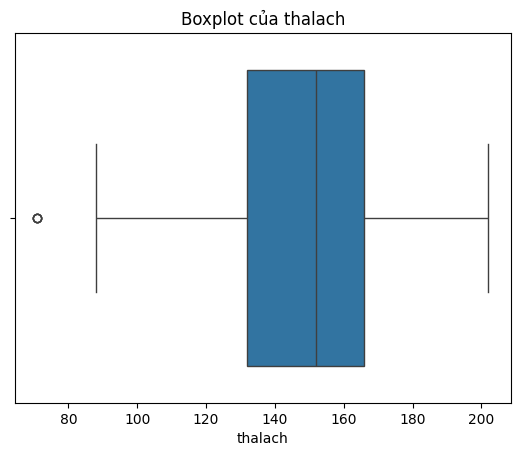

In [18]:
##Boxplot for thalach
sns.boxplot(x=numerical_data['thalach'])
plt.title("Boxplot của thalach")
plt.savefig("outputs/eda/Boxplot của thalach.png")
plt.show()

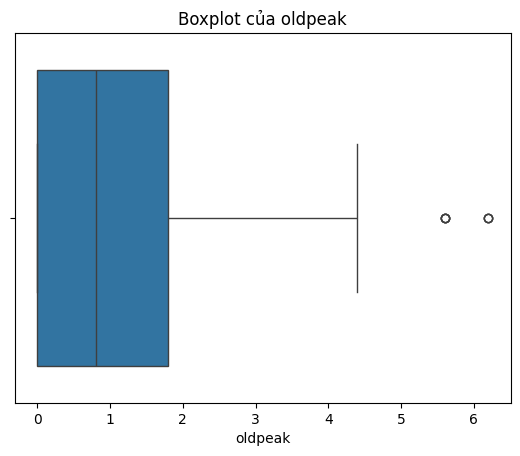

In [19]:
##Boxplot for oldpeak
sns.boxplot(x=numerical_data['oldpeak'])
plt.title("Boxplot của oldpeak")
plt.savefig("outputs/eda/Boxplot của oldpeakh.png")
plt.show()

Vì là dữ liệu y tế nên các outlier có thể là biểu hiện của bệnh nặng vì vậy không lựa chọn xoá bỏ mà chọn mô hình ít nhạy cảm với outlier để dự đoán.

## Categorical Features


**Unique value**

In [20]:
categorical_data.nunique()

cp         4
restecg    3
slope      3
thal       4
dtype: int64

In [21]:

for col in categorical_cols:
    print(f"Column :{col}")
    print(categorical_data[col].value_counts(dropna=False).to_dict())
    print("-" * 50)



Column :cp
{0: 497, 2: 284, 1: 167, 3: 77}
--------------------------------------------------
Column :restecg
{1: 513, 0: 497, 2: 15}
--------------------------------------------------
Column :slope
{1: 482, 2: 469, 0: 74}
--------------------------------------------------
Column :thal
{2: 544, 3: 410, 1: 64, 0: 7}
--------------------------------------------------


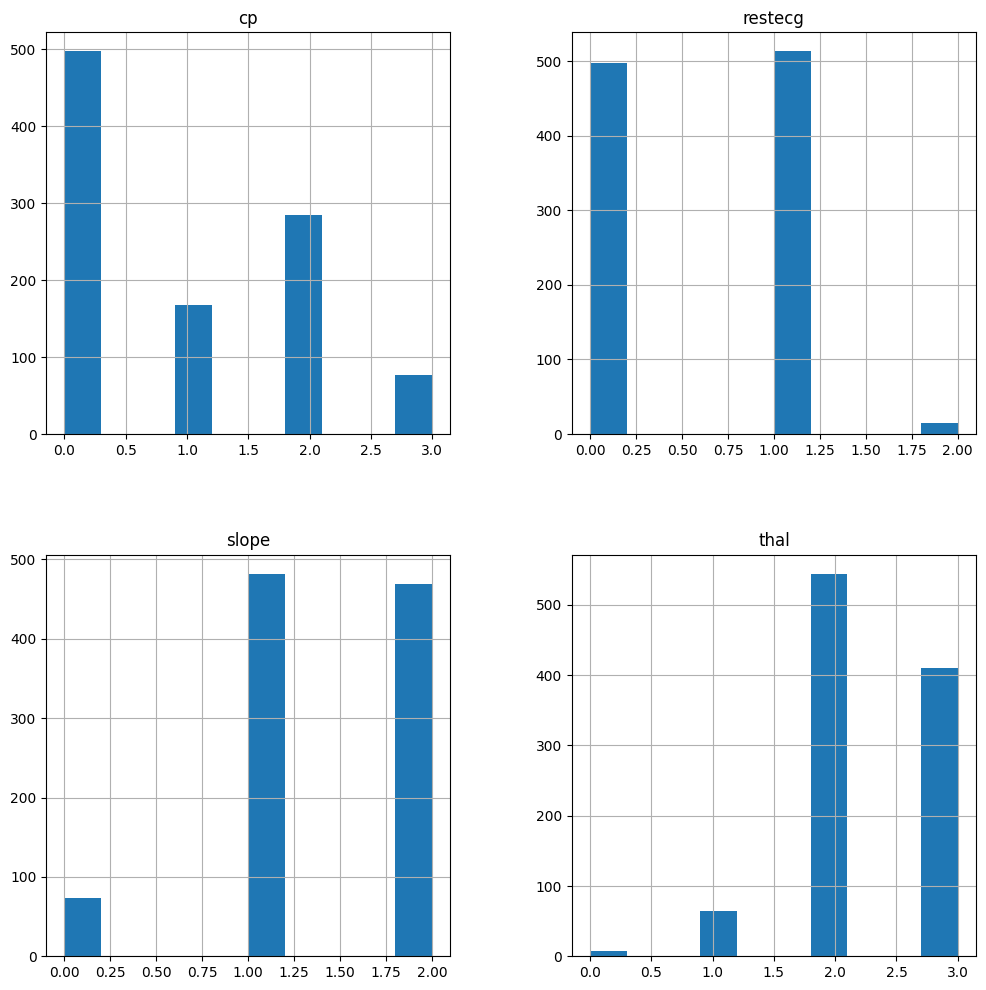

In [22]:

categorical_data.hist(figsize=(12,12),bins=10)
plt.savefig("outputs/eda/Histogram của categorical features.png")
plt.show()

## Correlation Analysis

**Tương quan giữa các numerical featuers với biến target**


In [23]:
from pandas import set_option
set_option('display.float_format', '{:,.3f}'.format)
correlation = numerical_data.corr(method='pearson')
correlation


,age,sex,trestbps,fbs,chol,thalach,exang,oldpeak,ca,target
age,1.000,-0.103,0.271,0.121,0.220,-0.390,0.088,0.208,0.272,-0.229
sex,-0.103,1.000,-0.079,0.027,-0.198,-0.049,0.139,0.085,0.112,-0.280
trestbps,0.271,-0.079,1.000,0.182,0.128,-0.039,0.061,0.187,0.105,-0.139
fbs,0.121,0.027,0.182,1.000,0.027,-0.009,0.049,0.011,0.137,-0.041
chol,0.220,-0.198,0.128,0.027,1.000,-0.022,0.067,0.065,0.074,-0.100
thalach,-0.390,-0.049,-0.039,-0.009,-0.022,1.000,-0.380,-0.350,-0.208,0.423
exang,0.088,0.139,0.061,0.049,0.067,-0.380,1.000,0.311,0.108,-0.438
oldpeak,0.208,0.085,0.187,0.011,0.065,-0.350,0.311,1.000,0.222,-0.438
ca,0.272,0.112,0.105,0.137,0.074,-0.208,0.108,0.222,1.000,-0.382
target,-0.229,-0.280,-0.139,-0.041,-0.100,0.423,-0.438,-0.438,-0.382,1.000


<function matplotlib.pyplot.show(close=None, block=None)>

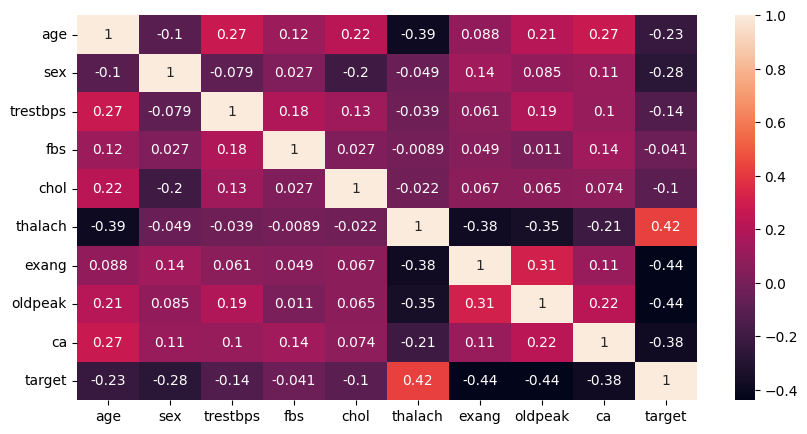

In [24]:
#Plot heatmap biểu diễn correlation matrix
fig,ax=plt.subplots(figsize=(10,5))
sns.heatmap(numerical_data.corr(),ax=ax,annot=True)
plt.savefig("outputs/eda/heatmap biểu diễn numerical correlation matrix.png")
plt.show

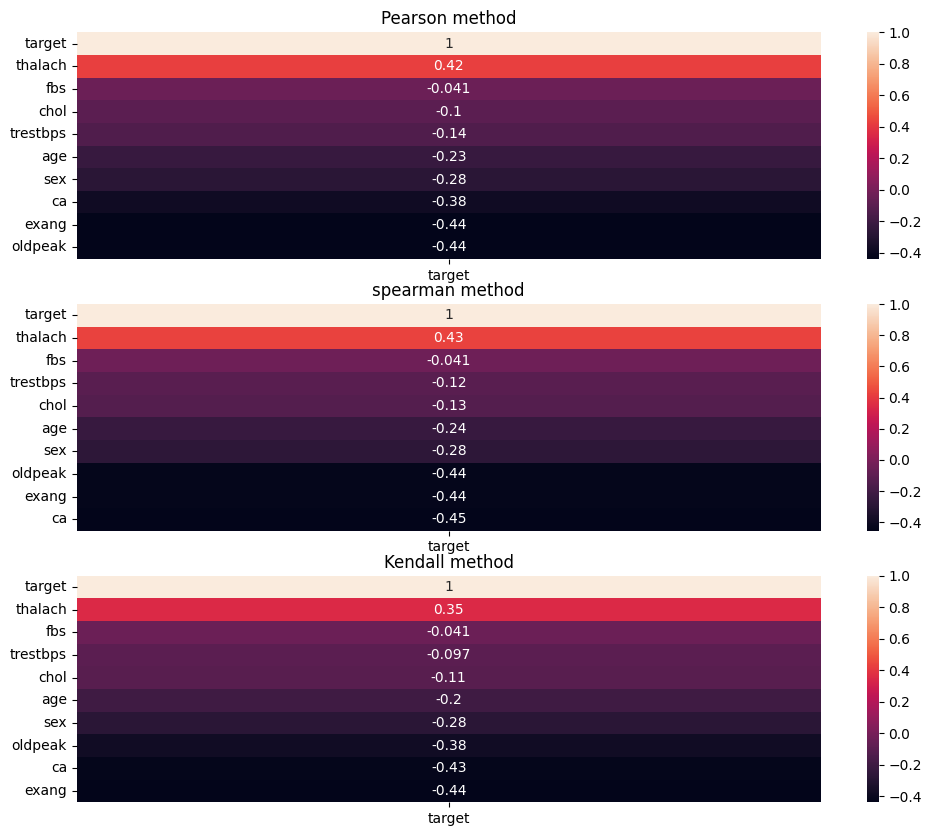

In [25]:
fig,ax=plt.subplots(3,1,figsize=(12,10))
corr1=numerical_data.corr('pearson')[['target']].sort_values(by='target',ascending=False)
corr2=numerical_data.corr('spearman')[['target']].sort_values(by='target',ascending=False)
corr3=numerical_data.corr('kendall')[['target']].sort_values(by='target',ascending=False)
ax[0].set_title('Pearson method')
ax[1].set_title('spearman method')
ax[2].set_title('Kendall method')

sns.heatmap(corr1, ax=ax[0], annot=True)
sns.heatmap(corr2, ax=ax[1], annot=True)
sns.heatmap(corr3, ax=ax[2], annot=True)
plt.show()


Các cặp biến độc lập có mối tương quan lớn hơn các cặp còn lại: age-thalach(ngược), thalach-exang(ngược), thalach-oldpeak(ngược)

- Tuổi càng cao thì nhịp tim tối đa càng thấp
- Nhịp tim tối đa càng thấp càng dễ bị đau thắt ngực
- Nhịp tim tối đa càng thấp thì độ chênh xuống của đoạn ST càng cao

Các biến có mối tương quan lớn đến biến mục tiêu: thalach, fbs,chol,trestbps,age

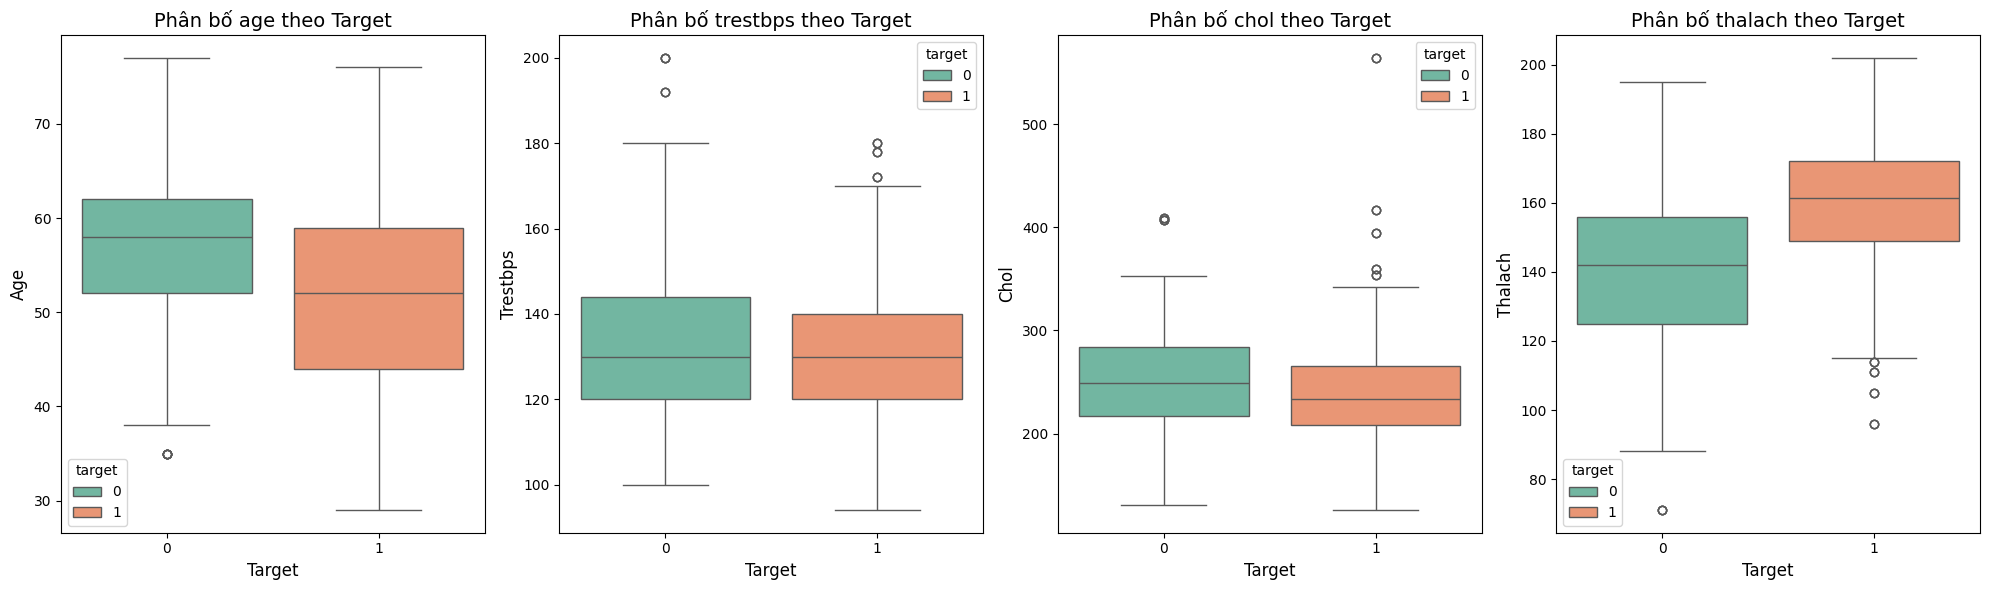

In [26]:
#Biểu đồ thể hiện tương quan của các biến 'age', 'trestbps', 'chol', 'thalach' theo từng nhóm target
continuous_features = ['age', 'trestbps', 'chol', 'thalach']
fig, axes = plt.subplots(1, 4, figsize=(20, 6))
axes = axes.flatten()
for i, col in enumerate(continuous_features):
    sns.boxplot(
        data=numerical_data, 
        x='target', 
        y=col, 
        ax=axes[i], 
        palette='Set2',
        hue='target'
    )
    axes[i].set_title(f'Phân bố {col} theo Target', fontsize=14)
    axes[i].set_xlabel('Target', fontsize=12)
    axes[i].set_ylabel(col.capitalize(), fontsize=12)
plt.savefig('outputs/eda/Biểu đồ phân phối age, trestbps, chol, thalach theo từng nhóm target.png')
plt.tight_layout()
plt.show()

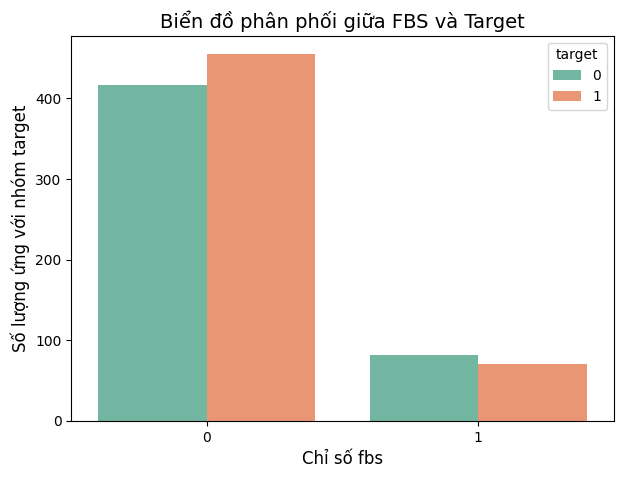

In [27]:
plt.figure(figsize=(7, 5))
sns.countplot(
    data=numerical_data, 
    x='fbs', 
    hue='target', 
    palette='Set2'
)
plt.title('Biển đồ phân phối giữa FBS và Target', fontsize=14)
plt.xlabel('Chỉ số fbs', fontsize=12)
plt.ylabel('Số lượng ứng với nhóm target', fontsize=12)
plt.savefig("outputs/eda/Biểu đồ phân phối giữa fbs với từng nhóm target.png")
plt.show()

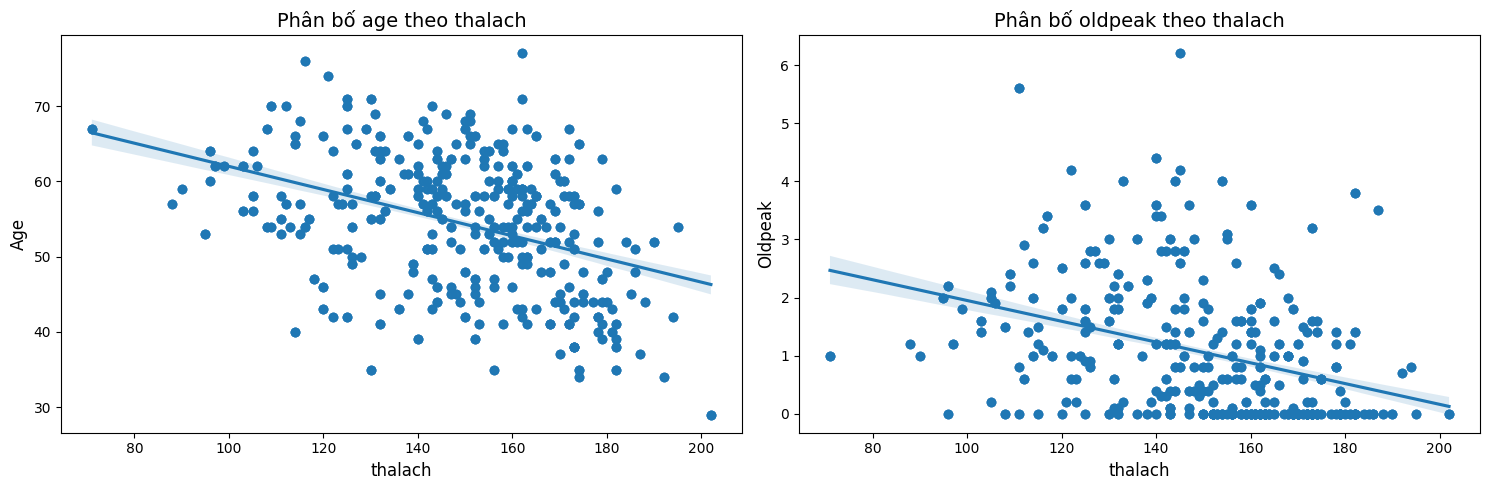

In [28]:
#Mối tương quan giuwxa age , oldpeak với thalach
features=['age','oldpeak']
fig, axes = plt.subplots(1,2, figsize=(15,5))
for i, col in enumerate(features):
    sns. regplot(data=numerical_data,
                x='thalach',
                y=col, 
                ax=axes[i]
                )
    axes[i].set_title(f'Phân bố {col} theo thalach', fontsize=14)
    axes[i].set_xlabel('thalach', fontsize=12)
    axes[i].set_ylabel(col.capitalize(), fontsize=12)
plt.tight_layout()
plt.savefig("outputs/eda/Mối tương quan giữa age, oldpeak với thalach")
plt.show()   




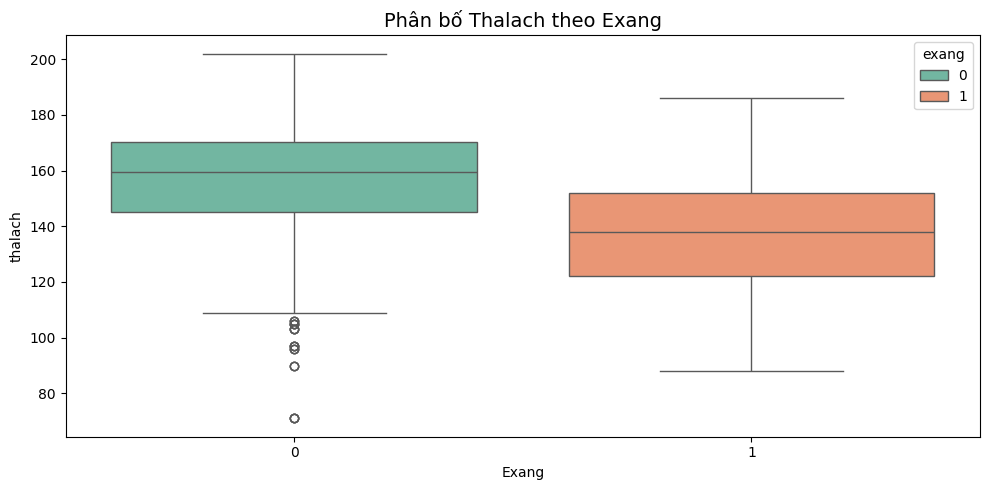

In [29]:
plt.figure(figsize=(10,5))
sns.boxplot(
    data=numerical_data, 
    x='exang', 
    y='thalach', 
    palette='Set2',
    hue='exang'
)
plt.title('Phân bố Thalach theo Exang', fontsize=14)
plt.xlabel('Exang')

plt.tight_layout()
plt.savefig("outputs/eda/Mối tương quan giữa exang-thalach.png")
plt.show()

**Tương quan giữa các biến categorical features với biến target**

In [30]:
data_copy=categorical_data.copy()
data_copy['target']=numerical_data['target']

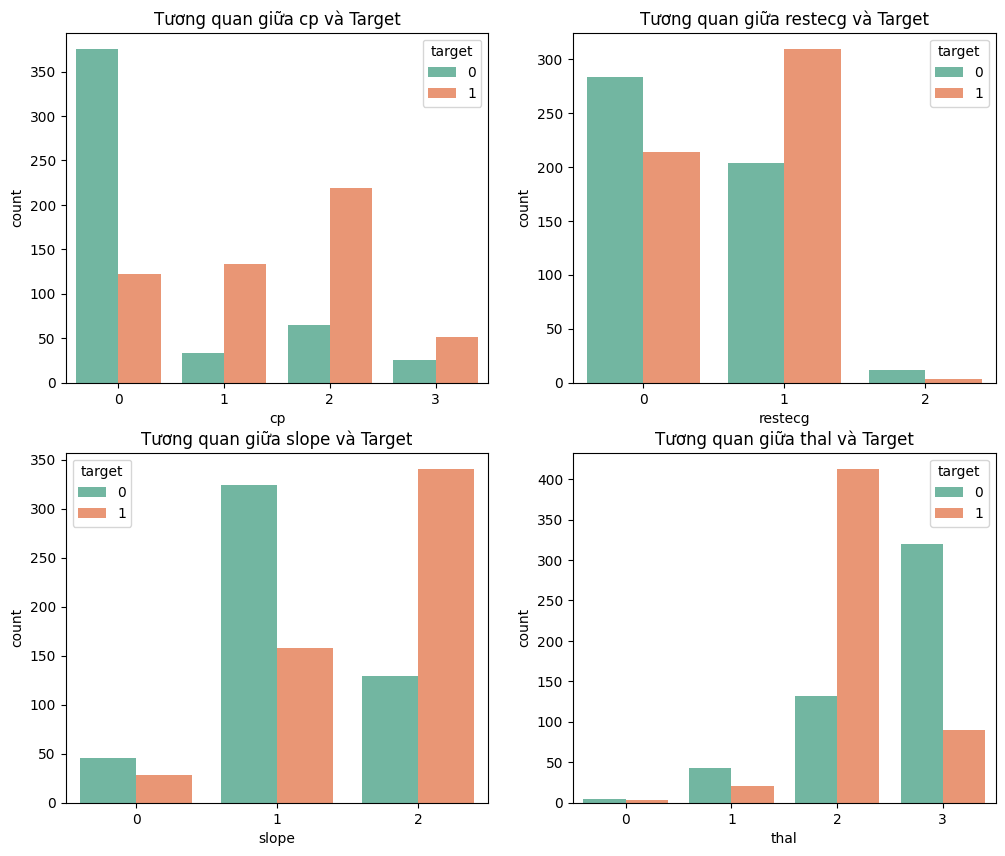

In [31]:
fig, axes = plt.subplots(2,2,figsize=(12,10))
axes = axes.flatten()
for i, col in enumerate(categorical_cols):
    sns.countplot(data=data_copy, x=col, hue='target', ax=axes[i], palette='Set2')
    axes[i].set_title(f'Tương quan giữa {col} và Target', fontsize=12)
plt.savefig('outputs/eda/Tương quan giữa các biến cateogical và target.png')
plt.show()

In [32]:
from sklearn.feature_selection import mutual_info_classif
import pandas as pd

# Tính Mutual Information
mi_scores = mutual_info_classif(categorical_data,data['target'], random_state=42)

# Tạo DataFrame để dễ nhìn
mi_scores_df = pd.DataFrame(
    {'Feature': categorical_cols, 'Mutual_Information_Score': mi_scores}
).sort_values(by='Mutual_Information_Score', ascending=False)
mi_scores 
print(mi_scores_df)

   Feature  Mutual_Information_Score
3     thal                     0.154
0       cp                     0.151
2    slope                     0.075
1  restecg                     0.023


Chỉ có tương quan giữa các biến độc lập cp,thal với biến target là cao hơn (do chỉ cố MI của 2 cặp này cao hơn )
- Biến cp MI=0,154: ở nhóm cp=0, cột target=0 cao vượt trội so với target=1. Ngược lại với nhóm cp=1,2 nhóm target=1 lại áp đảo hơn 
   
    ***->Việc biết trước cp sẽ phần nào đoán chính xác hơn kết quả biến target do ta đã bỏ bớt được sự hỗn loạn (Entropy) của target***
- Biến thal MI=0.151: ở nhóm thal=2,cột target=1 cao vượt trội. Còn ở nhóm thal =3 thì ngược lại cột target=0 cao hơn nhiều

  ***->Việc biết trước thal sẽ phần nào đoán chính xác hơn kết quả biến target do ta đã bỏ bớt được sự hỗn loạn (Entropy) của target***

- Biến slope MI=0.075: Ở slope = 1, target= 0 nhỉnh hơn Target 1 (tỷ lệ khoảng 2:1). Ở slope = 2, Target 1 lại vượt lên gấp đôi Target 0. 
Nó vẫn tạo ra sự phân tách giữa người bệnh và người khỏe, nhưng sự chênh lệch không cực đoan và dứt khoát như cp hay thal.
  
  ***-> Biến này vẫn mang lại giá trị dự đoán tốt và nên được giữ lại trong mô hình.***
- Biến restecg MI=0.023: ở cả hai nhóm chính (0 và 1), tỷ lệ Target 0 và Target 1 đều khá cân bằng, dù có cột nhỉnh hơn thì vẫn không đáng kể. Tuy nhiên do MI>0 nên vẫn có thể đưa vào mô hình

